# QAOA – universal template

Workflow: **problem → QUBO → Ising Hamiltonian → QAOA circuit → parameter optimization → sampling → evaluation**.

**How to use it**
1. Everything is set in the **⚙️ Configuration** cell. The other cells don't need to be changed.
2. The execution mode is chosen with the `MODE` variable:

   | `MODE` | what happens | IBM connection | quota |
   |---|---|---|---|
   | `"local"` | **simulation only**: exact, noiseless (Statevector), up to ~24 qubits | no | not used |
   | `"fake"` | **simulation only**: with the noise of a real processor (`FAKE_BACKEND`, default FakeMarrakesh) | no | not used |
   | `"hardware"` | a real IBM quantum computer | yes | used |

   The recommended order is `"local"` → `"fake"` → `"hardware"`. In `local` and `fake` modes the whole notebook runs without an IBM account and without internet.
3. This copy is set up for the **TSP** (closed tour, fixed start city). The problem lives in `build_problem` in section **2. Problem**.

**Safeguards against wasting quota**
- Nothing is sent to hardware until you set `RUN_ON_HARDWARE = True`.
- If the transpiled circuit has more than `MAX_2Q_GATES` two-qubit gates, the run stops. Such a circuit would return only noise on hardware.
- `MAXITER` limits the number of iterations and `MAX_TIME` the length of the session.
- ⚠️ **A session is billed for its entire duration**, including the time spent on classical computation between jobs. The `"job"` or `"batch"` mode bills only QPU time, but each job may wait in the queue.
- Large circuits are not drawn. A picture of a 100-qubit circuit was over 200 MB.

In [35]:
import time
from contextlib import nullcontext

import matplotlib.pyplot as plt
import numpy as np
import rustworkx as rx
from IPython.display import display
from rustworkx.visualization import mpl_draw as draw_graph
from scipy.optimize import minimize

from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import Batch, QiskitRuntimeService, Session, fake_provider
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import SamplerV2 as Sampler

from qiskit_addon_opt_mapper.applications import Tsp
from qiskit_addon_opt_mapper.converters import OptimizationProblemToQubo
from qiskit_addon_opt_mapper.translators import to_ising

## ⚙️ Configuration

In [36]:
# ── Graph ─────────────────────────────────────────────────────────────────────
GRAPH_KIND   = "manual"     # TSP needs a COMPLETE graph (all pairs); # "regular" | "random" | "ring" | "complete" | "native" | "manual"
N_NODES      = 5          # number of cities (TSP with fixed start needs (N-1)^2 qubits: 5 -> 16)
DEGREE       = 3           # "regular": every node has exactly DEGREE neighbors
EDGE_PROB    = 0.3         # "random":  probability of an edge between each pair of nodes
WEIGHTED     = True       # True = random edge weights from WEIGHT_RANGE, otherwise all 1.0
WEIGHT_RANGE = (0.1, 1.0)
MANUAL_EDGES = [(0, 1, 2676),
                (0, 2, 2768),
                (0, 3, 3937),
                (0, 4, 5136),
                (1, 2, 4471), 
                (1, 3, 221), 
                (1, 4, 4420), 
                (2, 3, 6134), 
                (2, 4, 7334), 
                (3, 4, 1387)]  # "manual": (i, j, weight)
SEED         = 42          # same SEED = same graph

START_CITY   = 0           # tour starts and ends here (fixed -> fewer qubits)

# ── QAOA and optimization ─────────────────────────────────────────────────────
REPS    = 3       # p = number of QAOA layers
MAXITER = 10000      # max. COBYLA iterations (= max. number of Estimator jobs)
RHOBEG  = 0.1     # initial COBYLA step size
TOL     = 1e-4

# ── Where to run ──────────────────────────────────────────────────────────────
MODE         = "local"          # "local"    = simulation only, exact, noiseless   (no IBM, free)
                                # "fake"     = simulation only, FAKE_BACKEND noise (no IBM, free)
                                # "hardware" = real IBM quantum computer           (uses quota)
BACKEND_NAME = None             # e.g. "ibm_marrakesh"; None = least busy processor
FAKE_BACKEND = "FakeMarrakesh"  # noise model for MODE="fake" (and topology for GRAPH_KIND="native")
EXECUTION    = "session"        # hardware only: "session" | "batch" | "job"
MAX_TIME     = "15m"            # max session/batch length – the whole duration is billed!
OPT_LEVEL    = 3                # transpiler optimization level

ESTIMATOR_SHOTS = 1_000
SAMPLER_SHOTS   = 10_000
JOB_TAGS        = ["QAOA_TEMPLATE"]

# ── Safeguards ────────────────────────────────────────────────────────────────
MAX_LOCAL_QUBITS = 24      # exact simulation needs ~2^n memory
MAX_2Q_GATES     = 2_000   # more two-qubit gates = practically pure noise on hardware
RUN_ON_HARDWARE  = False   # unless True, nothing is sent to real hardware

## 0. Backend

In [37]:
service = None
if MODE == "hardware":
    service = QiskitRuntimeService()
    backend = (service.backend(BACKEND_NAME) if BACKEND_NAME
               else service.least_busy(operational=True, simulator=False, min_num_qubits=N_NODES))
    print("Instance:", service.active_account().get("instance"))
elif MODE == "fake":
    backend = getattr(fake_provider, FAKE_BACKEND)()
elif MODE == "local":
    backend = None
else:
    raise ValueError(f"Unknown MODE: {MODE!r}")

# processor topology – needed for GRAPH_KIND="native" (FAKE_BACKEND is used in local mode)
topology = backend if backend is not None else getattr(fake_provider, FAKE_BACKEND)()
print("Mode:", MODE, "| backend:", backend.name if backend else "StatevectorEstimator (no noise)")
if MODE != "hardware":
    print("🖥  Simulation only – no IBM connection, quota is not used.")

Mode: local | backend: StatevectorEstimator (no noise)
🖥  Simulation only – no IBM connection, quota is not used.


## 1. Graph – automatic edge generation

| `GRAPH_KIND` | edges | suitable for hardware |
|---|---|---|
| `"regular"` | every node has exactly `DEGREE` neighbors (classic QAOA benchmark) | ✅ for small `DEGREE` |
| `"random"` | each pair of nodes with probability `EDGE_PROB` | ⚠️ only for small `EDGE_PROB` |
| `"ring"` | ring 0–1–2–…–(n−1)–0 | ✅ |
| `"complete"` | every node with every other | ❌ many SWAPs, results are noise |
| `"native"` | exactly copies the processor's qubit connectivity | ✅✅ the circuit needs no SWAPs |
| `"manual"` | `MANUAL_EDGES` | – |

Graph 'manual': 5 nodes, 10 edges, degree 4–4, connected: True


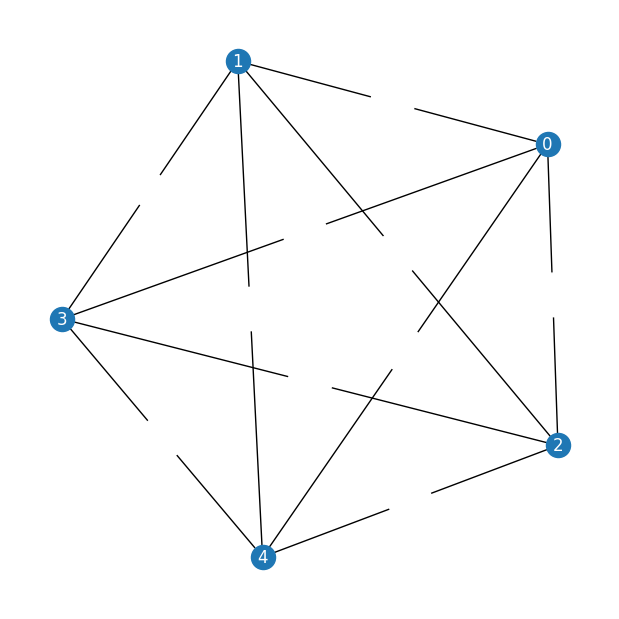

In [38]:
def random_regular_edges(n, d, rng, max_tries=2_000):
    # Random d-regular graph: random pairing of "stubs", repeated until the graph is valid.
    if not (0 < d < n) or (n * d) % 2:
        raise ValueError("A d-regular graph requires 0 < d < n and n·d even.")
    for _ in range(max_tries):
        stubs = rng.permutation(np.repeat(np.arange(n), d)).reshape(-1, 2)
        pairs = {tuple(sorted(map(int, p))) for p in stubs}
        if len(pairs) == len(stubs) and all(i != j for i, j in pairs):
            return sorted(pairs)
    raise RuntimeError("Failed to generate a d-regular graph – try a different SEED or a smaller DEGREE.")


def native_edges(backend, n, start_qubit=0):
    # n connected qubits chosen by breadth-first search (BFS) over the processor's coupling map.
    # Returns the edges (renumbered to 0..n-1) and the list of physical qubits for initial_layout.
    cmap = backend.coupling_map.graph.to_undirected(multigraph=False)
    order, seen, k = [start_qubit], {start_qubit}, 0
    while len(order) < n and k < len(order):
        for nb in sorted(cmap.neighbors(order[k])):
            if nb not in seen and len(order) < n:
                seen.add(nb)
                order.append(nb)
        k += 1
    if len(order) < n:
        raise ValueError(f"Processor {backend.name} does not have {n} connected qubits.")
    idx = {q: i for i, q in enumerate(order)}
    edges = sorted({tuple(sorted((idx[a], idx[b]))) for a, b in cmap.edge_list() if a in idx and b in idx})
    return edges, order


def make_edges(kind, n, rng):
    # Returns (list of edges, physical qubits or None).
    if kind == "regular":
        return random_regular_edges(n, DEGREE, rng), None
    if kind == "random":
        return [(i, j) for i in range(n) for j in range(i + 1, n) if rng.random() < EDGE_PROB], None
    if kind == "ring":
        return [(i, (i + 1) % n) for i in range(n)], None
    if kind == "complete":
        return [(i, j) for i in range(n) for j in range(i + 1, n)], None
    if kind == "native":
        return native_edges(topology, n)
    if kind == "manual":
        return MANUAL_EDGES, None
    raise ValueError(f"Unknown GRAPH_KIND: {kind!r}")


rng = np.random.default_rng(SEED)
raw_edges, physical_qubits = make_edges(GRAPH_KIND, N_NODES, rng)
edges = [(int(e[0]), int(e[1]),
          float(e[2]) if len(e) == 3 else (round(float(rng.uniform(*WEIGHT_RANGE)), 3) if WEIGHTED else 1.0))
         for e in raw_edges]
n_nodes = 1 + max(max(i, j) for i, j, _ in edges) if GRAPH_KIND == "manual" else N_NODES

graph = rx.PyGraph()
graph.add_nodes_from(range(n_nodes))
graph.add_edges_from(edges)

degrees = [graph.degree(v) for v in graph.node_indices()]
print(f"Graph '{GRAPH_KIND}': {graph.num_nodes()} nodes, {graph.num_edges()} edges, "
      f"degree {min(degrees)}–{max(degrees)}, connected: {rx.is_connected(graph)}")
if physical_qubits is not None:
    print("Physical qubits:", physical_qubits)

if n_nodes <= 60:
    plt.figure(figsize=(6, 6))
    draw_graph(graph, node_size=300 if n_nodes <= 30 else 60, with_labels=n_nodes <= 30,
               node_color="tab:blue", font_color="white",
               edge_labels=(lambda w: f"{w:g}") if WEIGHTED and n_nodes <= 20 else None)
    plt.show()

## 2. Problem → QUBO → Ising Hamiltonian  (TSP)

The TSP is encoded with binary variables `x[i,k] = 1` when city `i` is visited at position `k` of the tour.
The closed tour (return to the start) is built into the objective: position `n-1` is followed by position `0`.

Constraints (turned into penalties by `OptimizationProblemToQubo`): every city is visited exactly once, and every position holds exactly one city.

The start city is **fixed** at position 0, which removes the variables of that city and that position. This reduces `n²` to `(n-1)²` qubits (5 cities: 25 → 16).


In [39]:
def build_problem(graph):
    n = graph.num_nodes()
    # TSP needs a distance for every pair of cities
    if graph.num_edges() != n * (n - 1) // 2:
        raise ValueError("TSP needs a complete graph: use GRAPH_KIND='complete' or 'manual' with all pairs.")
    full = Tsp(graph).to_optimization_problem()          # n^2 variables x_i_k, closed tour
    s = START_CITY
    fixed = {f"x_{s}_0": 1}                              # start city sits at position 0
    fixed.update({f"x_{s}_{k}": 0 for k in range(1, n)})
    fixed.update({f"x_{i}_0": 0 for i in range(n) if i != s})
    return full.substitute_variables(fixed)              # (n-1)^2 variables left


PLOT_ON_GRAPH = True   # draw the best tour on the graph

problem   = build_problem(graph)
converter = OptimizationProblemToQubo()
qubo      = converter.convert(problem)
cost_hamiltonian, offset = to_ising(qubo)
n_qubits  = cost_hamiltonian.num_qubits
MAXIMIZE  = problem.objective.sense.name == "MAXIMIZE"

# which (city, position) every remaining variable stands for
var_cities = [tuple(int(t) for t in v.name.split("_")[1:]) for v in problem.variables]


def decode_route(x):
    # Bits (variable order of `problem`) -> closed tour [start, ..., start]; None if not a valid permutation.
    at = {k: i for (i, k), b in zip(var_cities, x) if b}
    if len(at) != n_nodes - 1 or sorted(at.values()) != sorted(set(range(n_nodes)) - {START_CITY}):
        return None
    return [START_CITY] + [at[k] for k in range(1, n_nodes)] + [START_CITY]


def objective_of(x):
    # Value of the original objective (tour length) and feasibility for bits x (variable i = qubit i).
    xs = converter.interpret(np.asarray(x))
    return float(problem.objective.evaluate(xs)), bool(problem.is_feasible(xs))


def energy_to_objective(e):
    # Ising Hamiltonian energy → value of the original objective (including penalties).
    q = e + offset
    return -q if MAXIMIZE else q


# Reference: random guessing (uniform distribution) and exact brute-force optimum (small n only)
E_uniform = float(sum(c.real for p, c in zip(cost_hamiltonian.paulis, cost_hamiltonian.coeffs)
                      if not (p.z.any() or p.x.any())))
E_opt = x_opt = None
if n_qubits <= 20:
    diag = np.real(cost_hamiltonian.to_matrix(sparse=True).diagonal())
    k = int(np.argmin(diag))
    E_opt, x_opt = float(diag[k]), [(k >> i) & 1 for i in range(n_qubits)]

print(f"Problem: {'maximization' if MAXIMIZE else 'minimization'}, {problem.get_num_vars()} variables "
      f"→ {n_qubits} qubits, {len(cost_hamiltonian)} Pauli terms, offset = {offset:g}")
print(f"Random guessing:  objective ≈ {energy_to_objective(E_uniform):g}  (includes penalties)")
if E_opt is not None:
    print(f"Exact optimum:    tour length = {energy_to_objective(E_opt):g}  route {decode_route(x_opt)}  (brute force)")

if MODE == "local" and n_qubits > MAX_LOCAL_QUBITS:
    raise RuntimeError(f"{n_qubits} qubits is too many for exact simulation (limit {MAX_LOCAL_QUBITS}). "
                       "Use fewer cities or MODE='fake'/'hardware'.")


Problem: minimization, 16 variables → 16 qubits, 100 Pauli terms, offset = 2.81586e+06
Random guessing:  objective ≈ 2.81586e+06  (includes penalties)
Exact optimum:    tour length = 13983  route [0, 4, 3, 1, 2, 0]  (brute force)


## 3. QAOA circuit and transpilation

After transpilation, check the **number of two-qubit gates**. With an error rate of roughly 10⁻³ per gate, thousands of gates are still usable, but tens of thousands return only noise.

Transpilation 0.0 s | two-qubit gates: 504 | 2q depth: 122 | total depth: 204


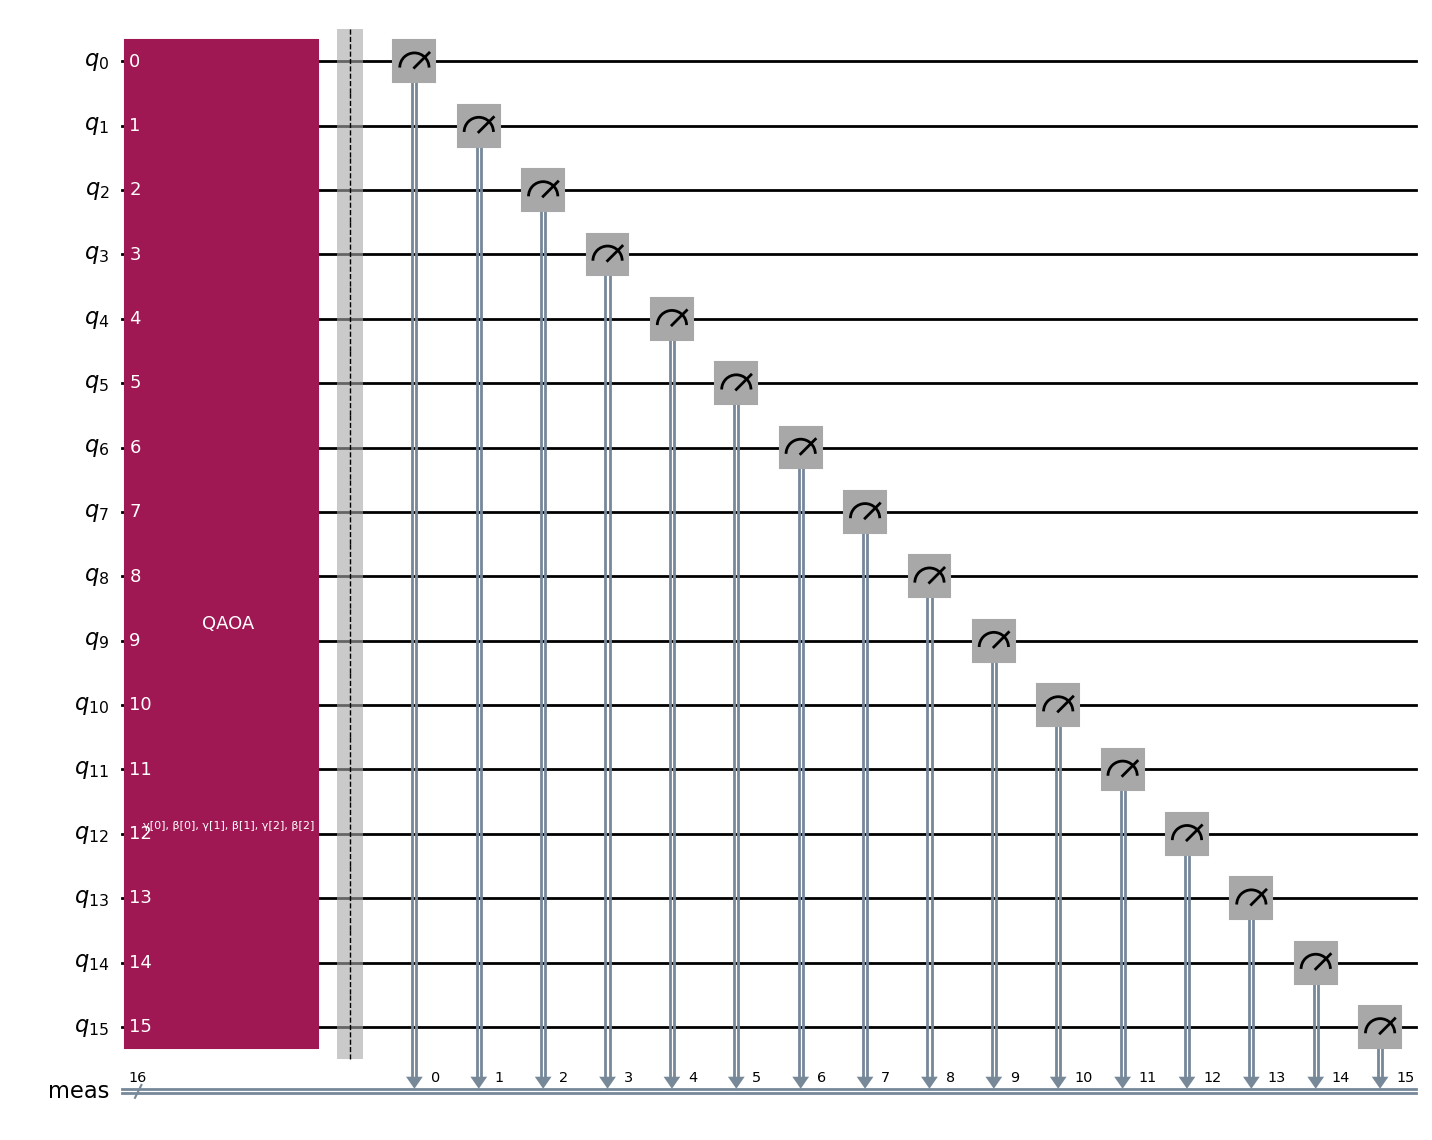

In [40]:
ansatz = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=REPS)
ansatz.measure_all()

if MODE == "local":
    pm = generate_preset_pass_manager(optimization_level=1, basis_gates=["rz", "sx", "x", "cx"])
else:
    use_native = physical_qubits is not None and len(physical_qubits) == n_qubits
    pm = generate_preset_pass_manager(optimization_level=OPT_LEVEL, backend=backend,
                                      initial_layout=physical_qubits if use_native else None,
                                      seed_transpiler=SEED)

t0 = time.perf_counter()
isa_sampler     = pm.run(ansatz)                                         # with measurement → Sampler
isa_estimator   = isa_sampler.remove_final_measurements(inplace=False)   # without measurement → Estimator
isa_hamiltonian = cost_hamiltonian.apply_layout(isa_estimator.layout)

n_2q  = sum(1 for inst in isa_estimator.data
            if inst.operation.num_qubits == 2 and inst.operation.name != "barrier")
depth = isa_estimator.depth(lambda inst: inst.operation.num_qubits == 2)
print(f"Transpilation {time.perf_counter() - t0:.1f} s | two-qubit gates: {n_2q} | "
      f"2q depth: {depth} | total depth: {isa_estimator.depth()}")

if MODE != "local" and n_2q > MAX_2Q_GATES:
    msg = (f"The circuit has {n_2q} two-qubit gates (limit MAX_2Q_GATES = {MAX_2Q_GATES}). The result would be noise – "
           "reduce the graph, lower the edge density or REPS, or use GRAPH_KIND='native'.")
    if MODE == "hardware":
        raise RuntimeError(msg)
    print("⚠️", msg)

if ansatz.num_qubits <= 16:
    display(ansatz.draw("mpl"))   # large circuits are deliberately not drawn (images can reach hundreds of MB)

## 4. Parameter optimization (COBYLA)

The initial point is a linear "ramp": γ gradually increases and β decreases, similar to an adiabatic transition. On hardware, an estimate of the total time is printed after the first iteration.

In [41]:
def initial_point(ansatz, reps, delta=0.6):
    # Values in the same order as ansatz.parameters (β[0..p-1], γ[0..p-1]).
    gamma_scale = 0.5 / max(abs(c) for c in cost_hamiltonian.coeffs)   # scaled by the size of the coefficients
    x0 = []
    for prm in ansatz.parameters:
        t = (prm.index + 0.5) / reps
        x0.append(delta * (1 - t) if prm.vector.name == "β" else delta * t * gamma_scale)
    return np.array(x0)


def configure(prim):
    # Error suppression and job tags – only meaningful on real hardware.
    if MODE == "hardware":
        prim.options.environment.job_tags = JOB_TAGS
        prim.options.dynamical_decoupling.enable = True
        prim.options.dynamical_decoupling.sequence_type = "XY4"
        prim.options.twirling.enable_gates = True
        prim.options.twirling.num_randomizations = "auto"
    return prim


def make_estimator(mode):
    if MODE == "local":
        return StatevectorEstimator()
    est = Estimator(mode=mode)
    est.options.default_shots = ESTIMATOR_SHOTS
    return configure(est)


def execution_context():
    if MODE == "hardware" and not RUN_ON_HARDWARE:
        raise RuntimeError("Safeguard: nothing is sent to hardware until you set RUN_ON_HARDWARE = True.")
    if MODE != "hardware" or EXECUTION == "job":
        return nullcontext(backend)
    return {"session": Session, "batch": Batch}[EXECUTION](backend=backend, max_time=MAX_TIME)


def fmt_params(values):
    return {p.name: round(float(v), 4) for p, v in zip(ansatz.parameters, values)}


def cost(params, estimator):
    t = time.perf_counter()
    res = estimator.run([(isa_estimator, isa_hamiltonian, params)]).result()[0]
    e, s = float(np.ravel(res.data.evs)[0]), float(np.ravel(res.data.stds)[0])
    history.append({"energy": e, "std": s, "params": np.array(params), "seconds": time.perf_counter() - t})
    k = len(history)
    print(f"iter {k:3d}  ⟨H⟩ = {e:+.4f} ± {s:.4f}  → objektiv ≈ {energy_to_objective(e):.4g}"
          f"  ({history[-1]['seconds']:.1f} s)")
    if k == 1 and MODE == "hardware":
        sec = history[0]["seconds"]
        print(f"   ⏱ estimate: up to {MAXITER} × {sec:.0f} s ≈ {MAXITER * sec / 60:.0f} min "
              f"(strop session/batch: {MAX_TIME})")
    return e

In [42]:
history = []
x0 = initial_point(ansatz, REPS)
print("Initial parameters:", fmt_params(x0))

t_start, interrupted, result, ctx = time.perf_counter(), False, None, execution_context()
with ctx as mode:
    estimator = make_estimator(mode)
    try:
        result = minimize(cost, x0, args=(estimator,), method="COBYLA", tol=TOL,
                          options={"maxiter": MAXITER, "rhobeg": RHOBEG})
    except KeyboardInterrupt:
        interrupted = True
        print("⏹ Interrupted – continuing with the best parameters measured so far.")

best_params = result.x if result is not None else min(history, key=lambda h: h["energy"])["params"]
print(f"\nDone: {len(history)} iterations in {(time.perf_counter() - t_start) / 60:.1f} min"
      + (f" | {result.message}" if result is not None else ""))
print("Optimal parameters:", fmt_params(best_params))
if isinstance(ctx, (Session, Batch)):
    try:
        print(f"Billed {EXECUTION} time: {ctx.usage()} s")
    except Exception as exc:
        print("Billed time cannot be determined yet:", exc)

Initial parameters: {'β[0]': 0.5, 'β[1]': 0.3, 'β[2]': 0.1, 'γ[0]': 0.0, 'γ[1]': 0.0, 'γ[2]': 0.0}
iter   1  ⟨H⟩ = +3446632.6553 ± 0.0000  → objektiv ≈ 6.262e+06  (0.4 s)
iter   2  ⟨H⟩ = +3412266.3720 ± 0.0000  → objektiv ≈ 6.228e+06  (0.4 s)
iter   3  ⟨H⟩ = +3745737.4155 ± 0.0000  → objektiv ≈ 6.562e+06  (0.4 s)
iter   4  ⟨H⟩ = +4650336.8156 ± 0.0000  → objektiv ≈ 7.466e+06  (0.4 s)
iter   5  ⟨H⟩ = +154.1257 ± 0.0000  → objektiv ≈ 2.816e+06  (0.5 s)
iter   6  ⟨H⟩ = -452.8705 ± 0.0000  → objektiv ≈ 2.815e+06  (0.4 s)
iter   7  ⟨H⟩ = -3439.1177 ± 0.0000  → objektiv ≈ 2.812e+06  (0.5 s)
iter   8  ⟨H⟩ = -5202.6093 ± 0.0000  → objektiv ≈ 2.811e+06  (0.5 s)
iter   9  ⟨H⟩ = -3932.2973 ± 0.0000  → objektiv ≈ 2.812e+06  (0.5 s)
iter  10  ⟨H⟩ = -5413.7546 ± 0.0000  → objektiv ≈ 2.81e+06  (0.5 s)
iter  11  ⟨H⟩ = +7458.8389 ± 0.0000  → objektiv ≈ 2.823e+06  (0.5 s)
iter  12  ⟨H⟩ = +808704.4075 ± 0.0000  → objektiv ≈ 3.625e+06  (0.5 s)
iter  13  ⟨H⟩ = -8448.1660 ± 0.0000  → objektiv ≈ 2.807e+06  (

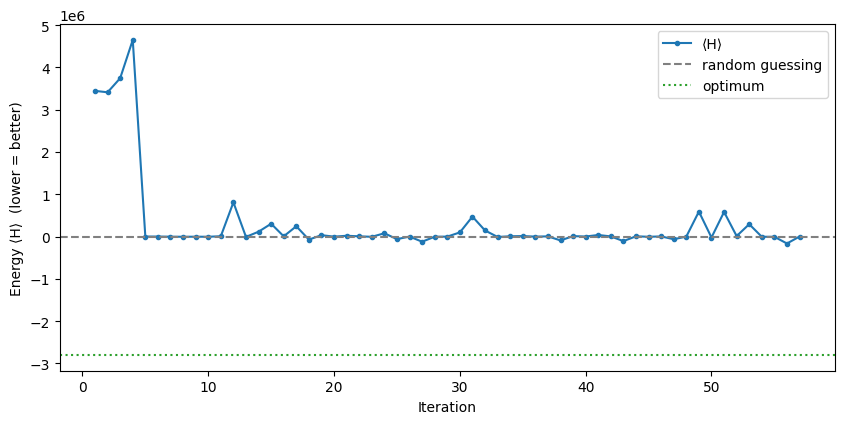

In [43]:
energies = np.array([h["energy"] for h in history])
stds     = np.array([h["std"] for h in history])
it       = np.arange(1, len(history) + 1)

plt.figure(figsize=(10, 4.5))
plt.plot(it, energies, "o-", ms=3, label="⟨H⟩")
if stds.any():
    plt.fill_between(it, energies - stds, energies + stds, alpha=0.2, label="± std")
plt.axhline(E_uniform, ls="--", c="gray", label="random guessing")
if E_opt is not None:
    plt.axhline(E_opt, ls=":", c="tab:green", label="optimum")
plt.xlabel("Iteration")
plt.ylabel("Energy ⟨H⟩  (lower = better)")
plt.legend()
plt.show()

## 5. Sampling with the optimal parameters

On hardware, sampling is sent as **a single standalone job**, not within the session. So only its QPU time is billed.

In [44]:
if MODE == "local":
    sampler = StatevectorSampler(default_shots=SAMPLER_SHOTS, seed=SEED)
else:
    if MODE == "hardware" and not RUN_ON_HARDWARE:
        raise RuntimeError("Safeguard: set RUN_ON_HARDWARE = True.")
    sampler = configure(Sampler(mode=backend))
    sampler.options.default_shots = SAMPLER_SHOTS

job = sampler.run([(isa_sampler, best_params)])
counts = job.result()[0].data.meas.get_counts()
shots = sum(counts.values())
print(f"{shots} samples, {len(counts)} distinct bitstrings")
if MODE == "hardware":
    print("Job:", job.job_id(), "| usage:", job.usage(), "s")

10000 samples, 8757 distinct bitstrings


## 6. Evaluation

In [45]:
# Qiskit bitstrings are little-endian: last character = qubit 0 = variable 0
samples = []
for bs, c in counts.items():
    x = np.array([int(b) for b in reversed(bs)])
    val, feas = objective_of(x)
    samples.append({"bits": bs, "x": x, "p": c / shots, "value": val, "feasible": feas})

sign = -1 if MAXIMIZE else 1
feasible = [s for s in samples if s["feasible"]] or samples
best     = min(feasible, key=lambda s: sign * s["value"])
likely   = max(samples, key=lambda s: s["p"])
mean_val = sum(s["p"] * s["value"] for s in samples)
p_feas   = sum(s["p"] for s in samples if s["feasible"])

print(f"Best sample:         {best['value']:g}   (p = {best['p']:.4f}, feasible: {best['feasible']})")
print(f"Most frequent sample: {likely['value']:g}   (p = {likely['p']:.4f})")
print(f"Mean value:          {mean_val:g}")
print(f"Feasible samples:    {p_feas:.1%}")
print(f"Random guessing:     {energy_to_objective(E_uniform):g}")
if E_opt is not None:
    opt_val = objective_of(x_opt)[0]
    p_opt = sum(s["p"] for s in samples if s["feasible"] and np.isclose(s["value"], opt_val))
    print(f"Optimum:             {opt_val:g}   → best sample / optimum = "
          f"{best['value'] / opt_val if opt_val else float('nan'):.3f}, "
          f"P(hit optimum) = {p_opt:.2%}")
print("Best route:          ", decode_route(best["x"]))
print("Best bits:           ", "".join(map(str, best["x"])))

Best sample:         13983   (p = 0.0001, feasible: True)
Most frequent sample: 78112   (p = 0.0005)
Mean value:          50255.4
Feasible samples:    0.1%
Random guessing:     2.81586e+06
Optimum:             13983   → best sample / optimum = 1.000, P(hit optimum) = 0.01%
Best route:           [0, 2, 1, 3, 4, 0]
Best bits:            0100100000100001


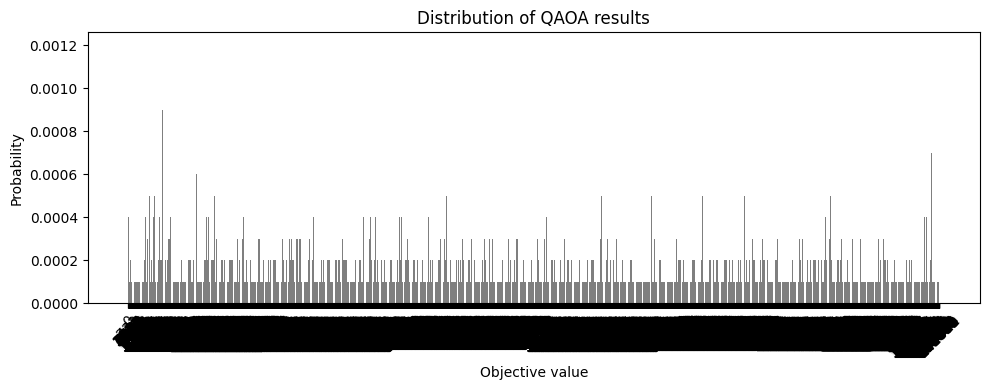

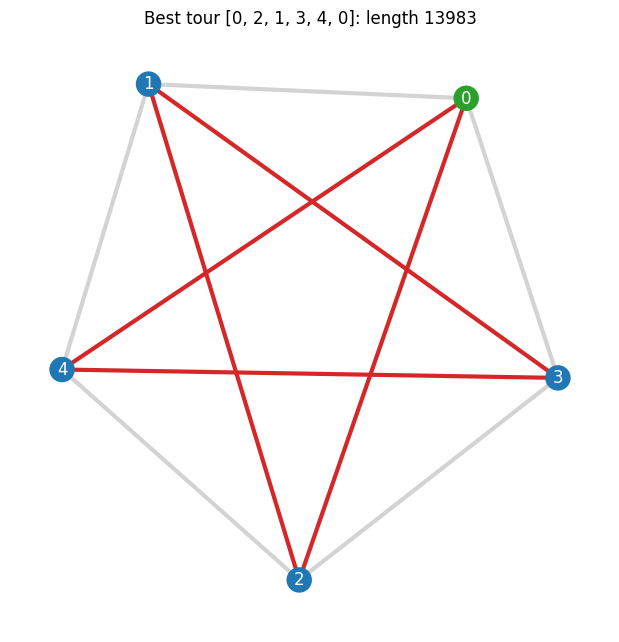

In [46]:
# distribution of objective values (weighted by probability)
vals = {}
for s in samples:
    vals[s["value"]] = vals.get(s["value"], 0) + s["p"]
xs = sorted(vals)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(xs)), [vals[v] for v in xs], color="tab:grey")
ax.set_xticks(range(len(xs)))
ax.set_xticklabels([f"{v:g}" for v in xs], rotation=45 if len(xs) > 15 else 0)
ax.set_xlabel("Objective value")
ax.set_ylabel("Probability")
ax.set_title("Distribution of QAOA results")
plt.tight_layout()
plt.show()

# best tour drawn on the graph (red edges = edges used by the tour)
route = decode_route(best["x"])
if PLOT_ON_GRAPH and n_nodes <= 60 and route is not None:
    tour = {tuple(sorted(e)) for e in zip(route[:-1], route[1:])}
    edge_colors = ["tab:red" if tuple(sorted(e)) in tour else "lightgray" for e in graph.edge_list()]
    node_colors = ["tab:green" if v == START_CITY else "tab:blue" for v in graph.node_indices()]
    plt.figure(figsize=(6, 6))
    draw_graph(graph, node_color=node_colors, edge_color=edge_colors, with_labels=n_nodes <= 30,
               node_size=300 if n_nodes <= 30 else 60, font_color="white", width=3)
    plt.title(f"Best tour {route}: length {best['value']:g}")
    plt.show()
elif route is None:
    print("Best sample is not a valid tour (increase REPS/MAXITER or the penalty).")


In [47]:
# remaining instance quota (rolling 28-day window)
if service is not None:
    u = service.usage()
    print(f"Consumed: {u['usage_consumed_seconds'] / 60:.0f} min | "
          f"remaining: {u['usage_remaining_seconds'] / 60:.0f} min of {u['usage_limit_seconds'] / 60:.0f} min")